## Import dependencies

In [1]:
import numpy as np
rng = np.random.default_rng()
import matplotlib.pyplot as plt
from objects_fast import Economy

## Run model for certain paramaters

In [2]:
# build neighbors
N = 1000
neighbors = np.ones((N,N))
alpha = 0.3
dep = 0.02
dt = 0.01
number_of_periods = 30000
initial_capital_pc = 50

In [3]:
update_freq = 6000

model_infrequent = Economy(N, N, initial_capital_pc, neighbors, update_freq, alpha, dep, dt, rng)

for _ in range(int(number_of_periods/dt)):
    model_infrequent.next_tick()

AttributeError: 'Economy' object has no attribute 'seed'

In [34]:
update_freq = 20

model_frequent = economy(N, N, 100, neighbors, update_freq, alpha, dep, dt)

for _ in range(int(number_of_periods/dt)):
    model_infrequent.next_period()

## Solow Golden Steady State

In [6]:
K_gold = (alpha/dep * N**(1-alpha))**(1/(1-alpha))

print("The golden rule level of capital = " + str(np.round(K_gold)))

The golden rule level of capital = 47877.0


## Plot key variables

### Capital

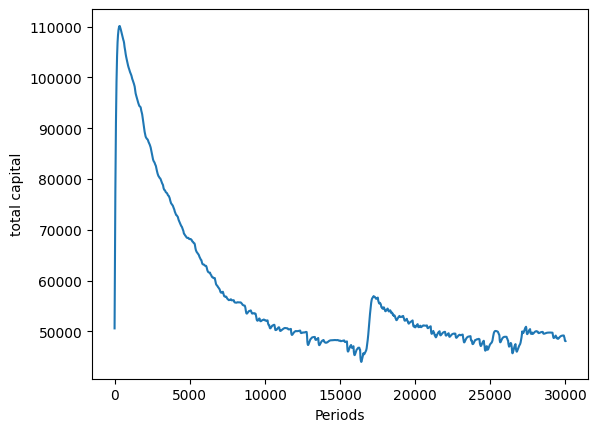

In [7]:
plt.plot(model_infrequent.total_capital_history)
plt.xlabel("Periods")
plt.ylabel("total capital")
plt.show()

### Convert data to numpy array

In [11]:
def convert_to_numpy_array(model):
    model.save_history = np.array(model.save_history)
    model.capital_history = np.array(model.capital_history)
    model.consumption_history = np.array(model.consumption_history)
    model.total_capital_history = np.array(model.total_capital_history)

In [12]:
convert_to_numpy_array(model_infrequent)

In [13]:
average_saving_rate = model_infrequent.save_history.mean(axis=1)

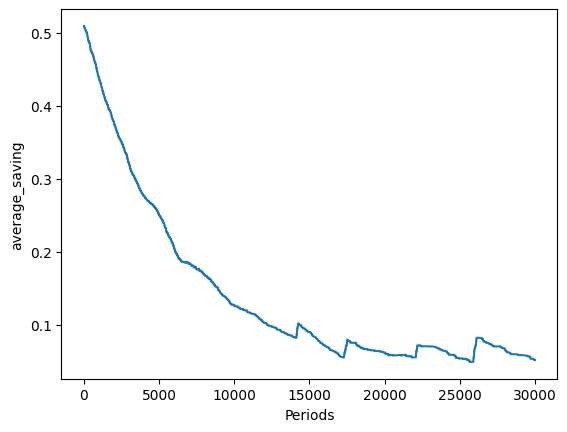

In [14]:
plt.plot(average_saving_rate)
plt.xlabel("Periods")
plt.ylabel("average_saving")
plt.show()

### Average Consumption Gini

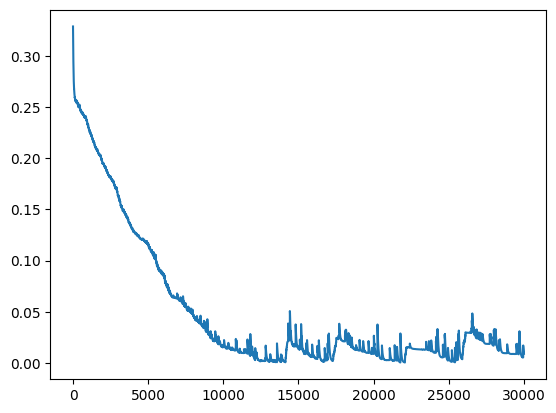

In [44]:
# Rows = years

# Sort consumptin from highest to lowest within each year
sorted_consumption = np.sort(model_infrequent.consumption_history)

# Find cumulative wealth and scale
cumulative = sorted_consumption.cumsum(axis = 1)
cumulative_scaled = cumulative/cumulative.max(axis = 1, keepdims = True)

# Calculate gini
gini = 1- 2* cumulative_scaled.sum(axis = 1)/N

# Plot gini
plt.plot(gini)